In [19]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

Transform: Convert Images into Tensors to normalize them

In [20]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5),(0.5))
])

Download and Load Data

In [21]:
train_set = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=64, shuffle=True)

test_set = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=64, shuffle=True)

Neural Network

In [22]:
class DigitModel(nn.Module):
  def __init__(self):
    super().__init__()
    #28x28 pixels = 784 input features
    self.main=nn.Sequential(
        nn.Linear(784,128),
        nn.ReLU(),
        nn.Linear(128,64),
        nn.ReLU(),
        nn.Linear(64,10)#10 output for digita 0-9
    )

  def forward(self,x):
    x=x.view(-1,784)
    return self.main(x)

model=DigitModel()

Training with CrossEntropyLoss

In [23]:
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(),lr=0.003)

#Training Loop
for epoch in range(5):
  for images, labels in train_loader:
    #Forward Pass
    outputs=model(images)
    loss = criterion(outputs,labels)

    #Backward Pass
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f"Epoch {epoch+1} completed. Loss: {loss.item():.4f}")

Epoch 5 completed. Loss: 0.3228


Testing AI Vision

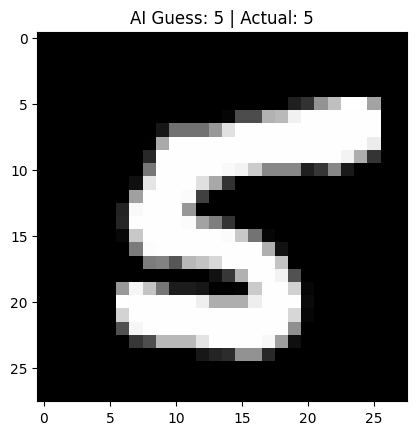

In [24]:
import matplotlib.pyplot as plt

# Grab one batch of test images
images, labels = next(iter(test_loader))

# Get a prediction for the first image
model.eval()
with torch.no_grad():
    output = model(images[0])
    prediction = torch.argmax(output) # Get the index of the highest probability

# Visualize
plt.imshow(images[0].numpy().squeeze(), cmap='gray')
plt.title(f"AI Guess: {prediction.item()} | Actual: {labels[0].item()}")
plt.show()

In [25]:
import torch

# 1. Save the "Model Weights" (Like your model.pkl)
torch.save(model.state_dict(), 'mnist_cnn_model.pth')

# 2. Create the 'requirements.txt'
with open('requirements.txt', 'w') as f:
    f.write("torch\ntorchvision\nmatplotlib\nnumpy")

# 3. Create the 'README.md'
readme_text = """# 🔢 MNIST Digit Prediction using CNN
This project uses a **Convolutional Neural Network** built in PyTorch to predict handwritten digits.

## 📁 Files
* `notebook.ipynb`: The full training process.
* `mnist_cnn_model.pth`: The trained model weights.
* `requirements.txt`: Libraries needed to run the code.
"""
with open('README.md', 'w') as f:
    f.write(readme_text)

print("Files created! Look in the folder icon on the left to download them.")

Files created! Look in the folder icon on the left to download them.


In [26]:
from google.colab import files

# List of files we created earlier
files_to_download = ['mnist_cnn_model.pth', 'requirements.txt', 'README.md']

for f in files_to_download:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>